In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (GroupShuffleSplit, StratifiedGroupKFold,
                                     cross_val_score)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (classification_report, roc_auc_score,
                             average_precision_score, confusion_matrix)


In [96]:
df = pd.read_csv('../data/kenya_synthetic_loans.csv')
print(df.shape)
print(df.columns.tolist())
display(pd.concat([df.head(), df.tail()]))

(5000, 18)
['loan_id', 'borrower_id', 'age', 'county', 'employment_type', 'monthly_income_kes', 'mpesa_avg_monthly_inflow_kes', 'mpesa_account_age_months', 'airtime_spend_monthly_kes', 'prior_loans', 'prior_defaults', 'active_loans_elsewhere', 'loan_amount_kes', 'term_days', 'fee_pct', 'channel', 'loan_to_income', 'defaulted_90dpd']


,loan_id,borrower_id,age,county,employment_type,monthly_income_kes,mpesa_avg_monthly_inflow_kes,mpesa_account_age_months,airtime_spend_monthly_kes,prior_loans,prior_defaults,active_loans_elsewhere,loan_amount_kes,term_days,fee_pct,channel,loan_to_income,defaulted_90dpd
0,L02765,B01921,41,Eldoret,Salaried,33300,22700,18,2300,0,0,0,15000,30,10.3,Mobile App,0.450,0
1,L04768,B03336,30,Mombasa,Salaried,116600,138700,57,3160,0,0,3,8100,21,6.8,Mobile App,0.069,0
2,L03815,B02652,44,Mombasa,Salaried,47300,64400,34,2890,0,0,0,18000,90,19.6,Mobile App,0.381,0
3,L03500,B02428,32,Machakos,Casual,16000,19600,49,680,0,0,1,5000,30,11.4,Mobile App,0.312,0
4,L02736,B01898,28,Nairobi,Self-employed,39600,50200,47,1830,0,0,1,10700,21,7.1,Mobile App,0.270,0
4995,L02896,B02007,22,Eldoret,Self-employed,42000,27200,8,1760,0,0,0,2600,60,14.4,Mobile App,0.062,0
4996,L02764,B01920,22,Nairobi,Self-employed,75600,75100,59,2120,0,0,2,14700,90,17.9,Bank digital,0.194,0
4997,L00906,B00629,18,Mombasa,Casual,8900,11900,41,480,2,1,3,4200,14,8.0,Mobile App,0.472,0
4998,L03981,B02773,31,Nakuru,Salaried,61900,48500,78,3460,0,0,1,9100,14,12.3,Mobile App,0.147,0
4999,L00236,B00167,35,Nairobi,Casual,17900,17700,46,780,0,0,4,13700,7,13.0,Mobile App,0.765,1


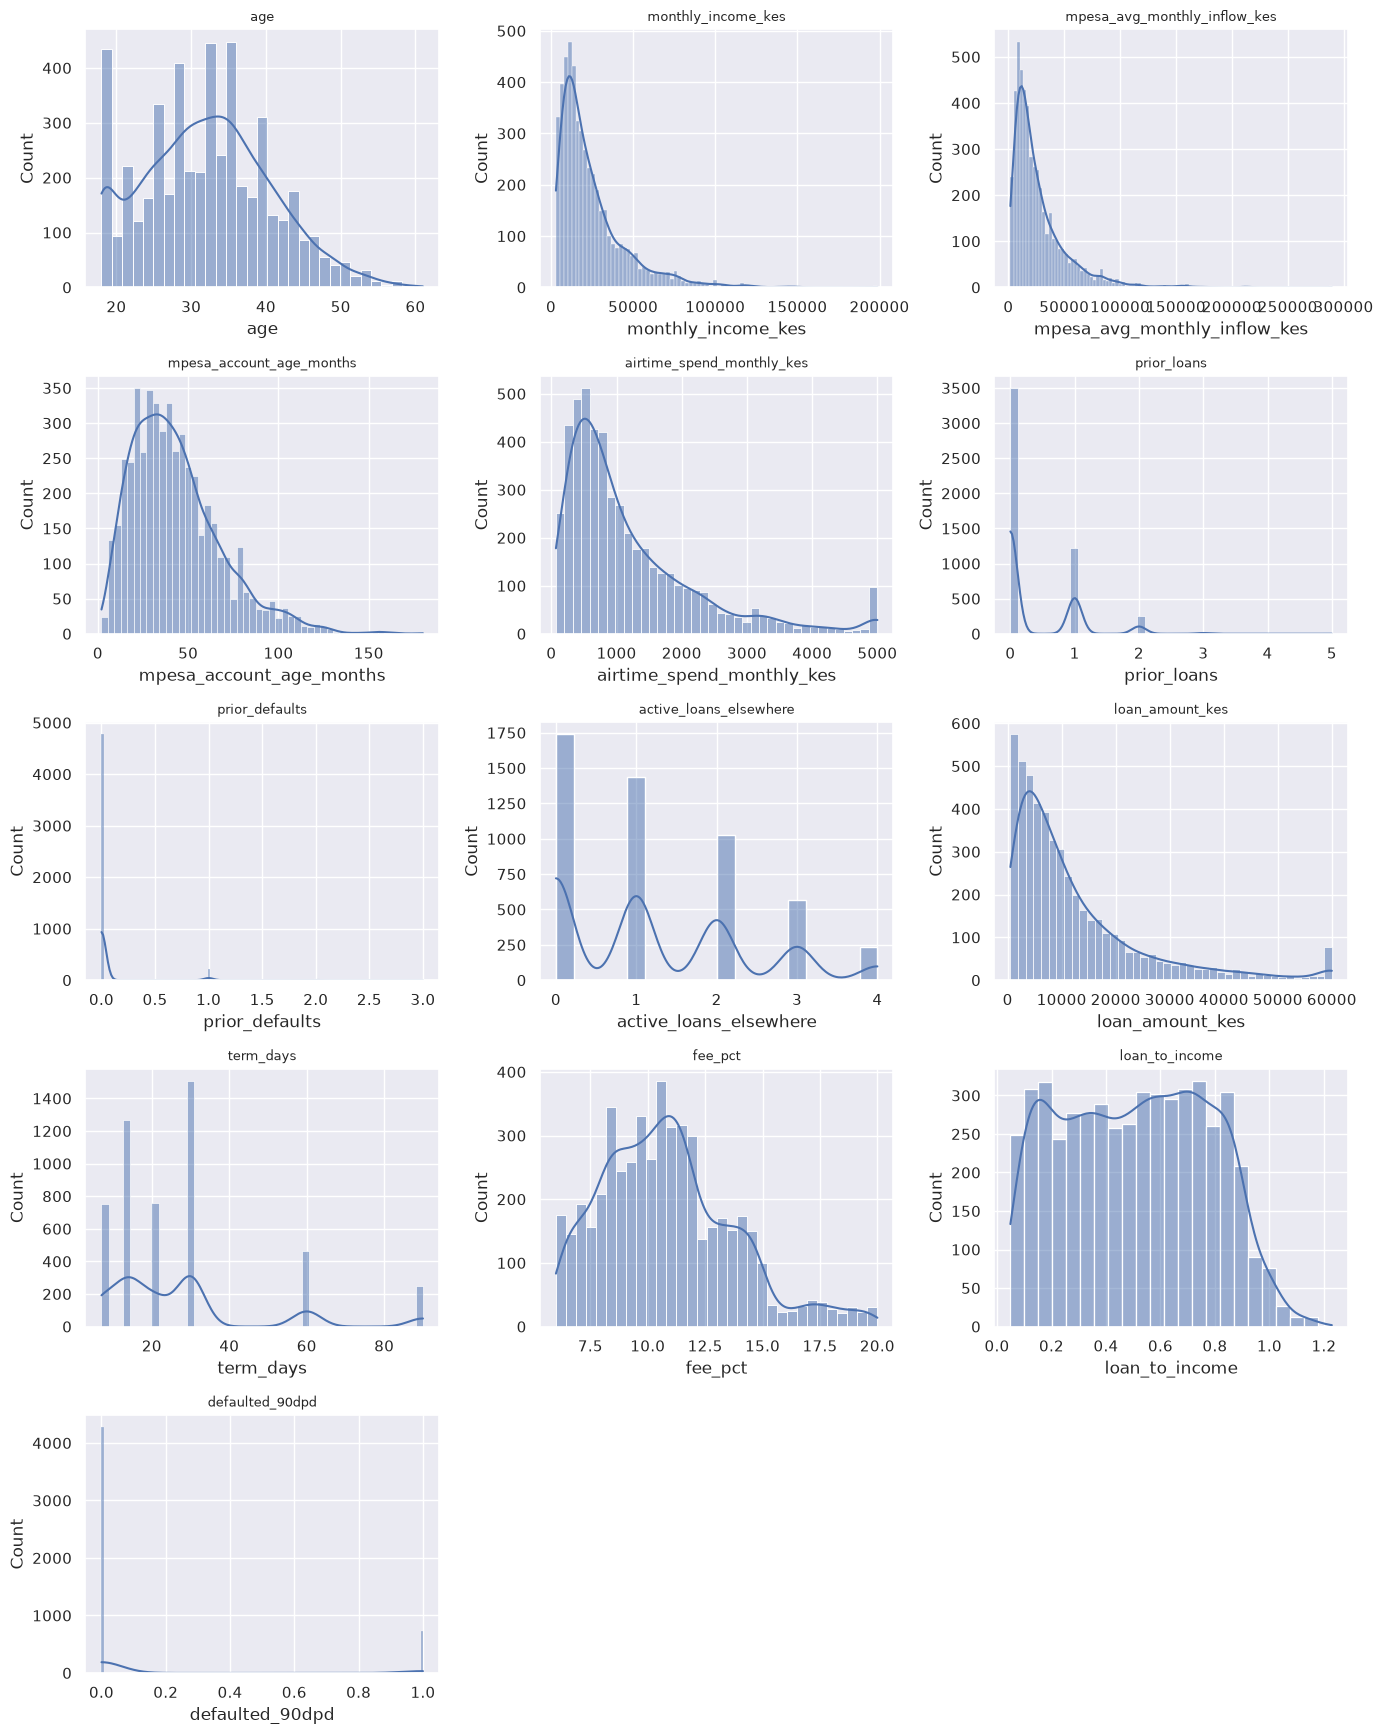

In [97]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

n = len(numeric_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
axes = axes.flat

for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col, fontsize=9)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [98]:
for col in ["county", "employment_type", "channel"]:
    df[col] = pd.Categorical(df[col]).codes

In [99]:
data = df.copy()
groups = data["borrower_id"]
y = data["defaulted_90dpd"]
X = data.drop(columns=["loan_id", "borrower_id", "defaulted_90dpd"])


In [100]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[tr], X.iloc[te]
y_train, y_test = y.iloc[tr], y.iloc[te]

print(f"train={len(X_train)}  test={len(X_test)}  "
      f"default rate train={y_train.mean():.3f} test={y_test.mean():.3f}")


train=4000  test=1000  default rate train=0.147 test=0.139


In [101]:
tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42,
)
tree.fit(X_train, y_train)

y_pred  = tree.predict(X_test)
y_proba = tree.predict_proba(X_test)[:, 1]

print("Accuracy:", tree.score(X_test, y_test))
print("ROC-AUC :", roc_auc_score(y_test, y_proba))
print("PR-AUC  :", average_precision_score(y_test, y_proba))
print()
print(classification_report(y_test, y_pred, digits=3))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 0.673
ROC-AUC : 0.6816818322345608
PR-AUC  : 0.27202266723078217

              precision    recall  f1-score   support

           0      0.910     0.689     0.784       861
           1      0.230     0.576     0.329       139

    accuracy                          0.673      1000
   macro avg      0.570     0.632     0.556      1000
weighted avg      0.815     0.673     0.721      1000

Confusion matrix:
 [[593 268]
 [ 59  80]]



True grouped CV ROC-AUC: 0.685 ± 0.027
|--- active_loans_elsewhere <= 1.50
|   |--- loan_to_income <= 0.47
|   |   |--- monthly_income_kes <= 24850.00
|   |   |   |--- fee_pct <= 16.10
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- fee_pct >  16.10
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- monthly_income_kes >  24850.00
|   |   |   |--- loan_to_income <= 0.21
|   |   |   |   |--- class: 0
|   |   |   |--- loan_to_income >  0.21
|   |   |   |   |--- truncated branch of depth 2
|   |--- loan_to_income >  0.47
|   |   |--- monthly_income_kes <= 23750.00
|   |   |   |--- active_loans_elsewhere <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- active_loans_elsewhere >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- monthly_income_kes >  23750.00
|   |   |   |--- employment_type <= 1.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- employment_type >  1.50
|   |   |   |   |--- truncated bra

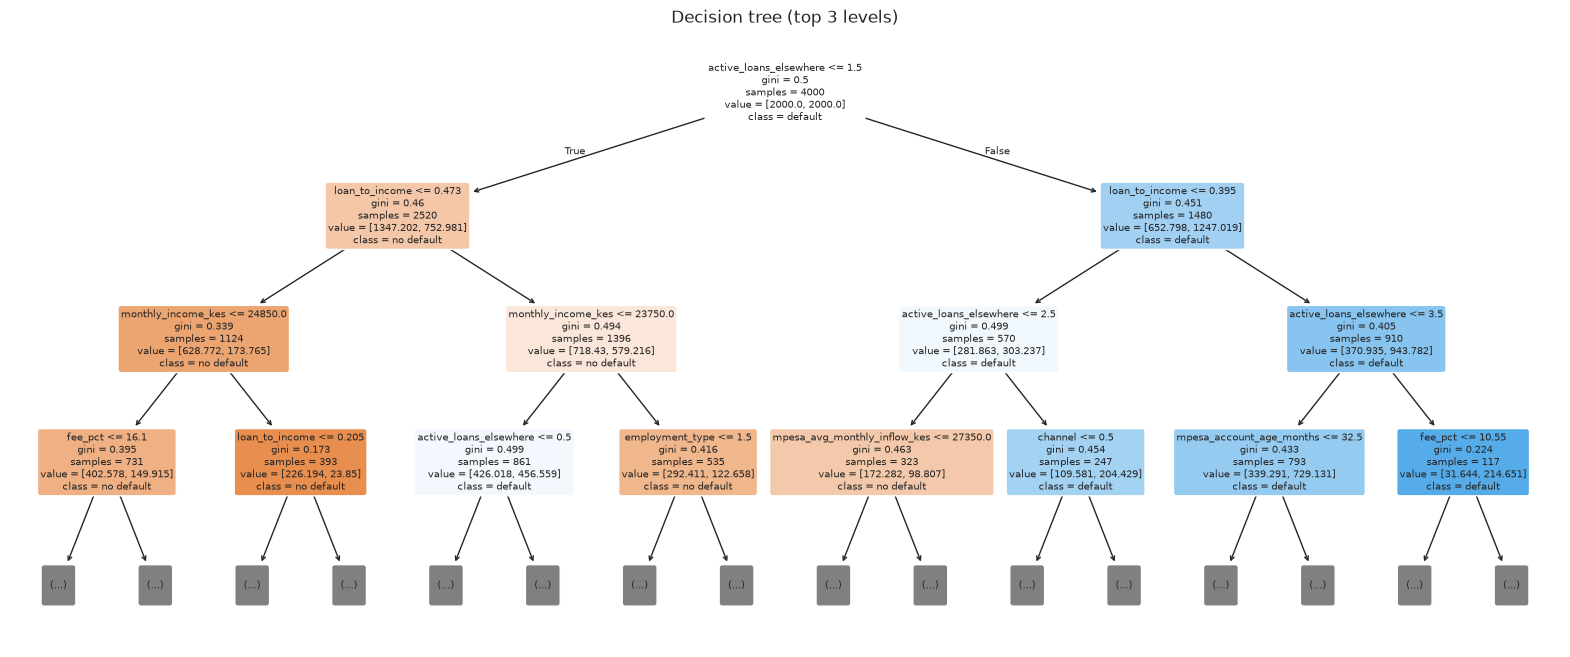

In [102]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(tree, X, y, cv=cv, groups=groups, scoring="roc_auc")
print(f"\nTrue grouped CV ROC-AUC: {scores.mean():.3f} ± {scores.std():.3f}")
print(export_text(tree, feature_names=list(X.columns), max_depth=3))
plt.figure(figsize=(20, 8))
plot_tree(tree, feature_names=X.columns,
          class_names=["no default", "default"],
          filled=True, rounded=True, fontsize=7, max_depth=3)
plt.title("Decision tree (top 3 levels)")
plt.show()


In [105]:
grid_results = []
for max_depth in [5, 8, 10]:
    for min_samples_leaf in [10, 20]:
        candidate = DecisionTreeClassifier(
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            class_weight="balanced",
            random_state=42,
        )
        candidate.fit(X_train, y_train)
        candidate_proba = candidate.predict_proba(X_test)[:, 1]
        grid_results.append({
            "max_depth": max_depth,
            "min_samples_leaf": min_samples_leaf,
            "test_roc_auc": roc_auc_score(y_test, candidate_proba),
            "test_pr_auc": average_precision_score(y_test, candidate_proba),
        })

grid_results = pd.DataFrame(grid_results).sort_values("test_pr_auc", ascending=False)
print(grid_results.to_string(index=False, formatters={
    "test_roc_auc": "{:.3f}".format,
    "test_pr_auc": "{:.3f}".format,
}))


 max_depth  min_samples_leaf test_roc_auc test_pr_auc
         5                10        0.683       0.275
         5                20        0.682       0.272
         8                10        0.655       0.245
         8                20        0.654       0.236
        10                20        0.658       0.233
        10                10        0.629       0.217


In [106]:
X_no_ratio = X.drop(columns=["loan_to_income"])
X_ratio_only = X.drop(columns=["loan_amount_kes", "monthly_income_kes"])

feature_sets = {
    "raw_plus_ratio": X,
    "raw_without_ratio": X_no_ratio,
    "ratio_without_raws": X_ratio_only,
}
comparison_rows = []
for name, X_variant in feature_sets.items():
    variant_scores = {}
    for scoring in ["roc_auc", "average_precision"]:
        variant_tree = DecisionTreeClassifier(
            max_depth=8,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42,
        )
        scores = cross_val_score(
            variant_tree, X_variant, y, cv=cv, groups=groups, scoring=scoring
        )
        variant_scores[f"grouped_{scoring}"] = scores.mean()
        variant_scores[f"grouped_{scoring}_std"] = scores.std()

    train_variant, test_variant = X_variant.iloc[tr], X_variant.iloc[te]
    variant_tree = DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
    )
    variant_tree.fit(train_variant, y_train)
    variant_proba = variant_tree.predict_proba(test_variant)[:, 1]
    variant_scores["test_roc_auc"] = roc_auc_score(y_test, variant_proba)
    variant_scores["test_pr_auc"] = average_precision_score(y_test, variant_proba)
    comparison_rows.append({"feature_set": name, **variant_scores})

comparison = pd.DataFrame(comparison_rows).sort_values("grouped_average_precision", ascending=False)
print(comparison.to_string(index=False, formatters={
    column: "{:.3f}".format
    for column in comparison.columns
    if column != "feature_set"
}))


       feature_set grouped_roc_auc grouped_roc_auc_std grouped_average_precision grouped_average_precision_std test_roc_auc test_pr_auc
ratio_without_raws           0.657               0.029                     0.273                         0.029        0.641       0.240
    raw_plus_ratio           0.655               0.024                     0.266                         0.025        0.655       0.245
 raw_without_ratio           0.634               0.026                     0.248                         0.027        0.634       0.232
